In [5]:
import cv2
import os
import glob
import numpy as np

save_dir = "data/raw/chrysocolla_malachite"
os.makedirs(save_dir, exist_ok=True)

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

saved_files = sorted(glob.glob(os.path.join(save_dir, "cm_*.png")))
img_counter = len(saved_files)

window_title = "SPEC-0002 Capture (Targeting Rich Mineral Zones)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Look for rich color contacts (Azurite / Chrysocolla / Malachite).")

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    # Compute color richness (Mean Saturation in HSV space)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    color_score = float(np.mean(sat))

    display_frame = frame.copy()
    
    # Visual indicator: Green when framing vivid mineral zones, Yellow when plain
    status_color = (0, 255, 0) if color_score > 35 else (0, 200, 255)
    overlay_text = f"Saved: {img_counter} | Color Score: {color_score:.1f}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, status_color, 2, cv2.LINE_AA)
    
    if color_score <= 35:
        cv2.putText(display_frame, "Plain matrix area - pan to color zone", (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 165, 255), 2, cv2.LINE_AA)

    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q') or key == 27:
        break
    elif key == 32:  # SPACE
        img_counter += 1
        filepath = os.path.join(save_dir, f"cm_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        print(f"Captured: {filepath} (Color Score: {color_score:.1f})")
    elif key in (ord('d'), ord('D')):
        if saved_files:
            last = saved_files.pop()
            if os.path.exists(last):
                os.remove(last)
                img_counter -= 1
                print(f"Deleted: {last}")

cap.release()
cv2.destroyAllWindows()
print(f"Collection complete: {len(saved_files)} color-rich frames saved.")

Look for rich color contacts (Azurite / Chrysocolla / Malachite).
Captured: data/raw/chrysocolla_malachite\cm_001.png (Color Score: 80.9)
Captured: data/raw/chrysocolla_malachite\cm_002.png (Color Score: 83.6)
Captured: data/raw/chrysocolla_malachite\cm_003.png (Color Score: 68.8)
Captured: data/raw/chrysocolla_malachite\cm_004.png (Color Score: 72.3)
Captured: data/raw/chrysocolla_malachite\cm_005.png (Color Score: 79.2)
Captured: data/raw/chrysocolla_malachite\cm_006.png (Color Score: 97.3)
Captured: data/raw/chrysocolla_malachite\cm_007.png (Color Score: 105.0)
Captured: data/raw/chrysocolla_malachite\cm_008.png (Color Score: 110.4)
Captured: data/raw/chrysocolla_malachite\cm_009.png (Color Score: 111.5)
Captured: data/raw/chrysocolla_malachite\cm_010.png (Color Score: 93.5)
Captured: data/raw/chrysocolla_malachite\cm_011.png (Color Score: 84.2)
Captured: data/raw/chrysocolla_malachite\cm_012.png (Color Score: 90.4)
Captured: data/raw/chrysocolla_malachite\cm_013.png (Color Score: 8

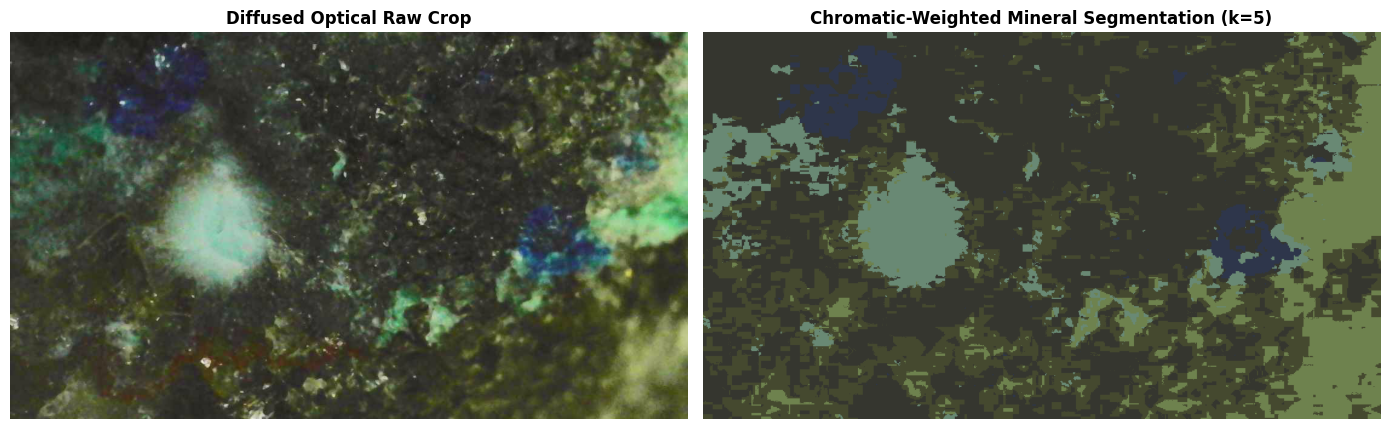

Phase Surface Breakdown (Identified by Mean RGB):
  Phase 1 (RGB: [53, 54, 47]): 49.97%
  Phase 2 (RGB: [69, 73, 47]): 26.70%
  Phase 3 (RGB: [105, 137, 116]): 8.46%
  Phase 4 (RGB: [110, 130, 78]): 11.73%
  Phase 5 (RGB: [46, 54, 75]): 3.14%


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load crop
crop_bgr = crop.copy() if 'crop' in locals() else cv2.imread("data/raw/chrysocolla_malachite/cm_001.png")[40:-40, 80:-80]
crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)

# 2. Convert to CIE-Lab float
lab = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)

# Weight channels: L* (lightness) reduced to 0.3, a* (green-red) x 2.5, b* (blue-yellow) x 3.0
# This prevents dark brightness gradients from stealing clusters from vivid blue/green phases
weights = np.array([0.3, 2.5, 3.0], dtype=np.float32)
weighted_pixels = (lab * weights).reshape(-1, 3)

# 3. Fit K-Means with 5 distinct geological phases
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(weighted_pixels)

# Reconstruct unweighted cluster centers in RGB space for authentic display
centers_rgb = np.zeros((k, 3), dtype=np.uint8)
for i in range(k):
    mask = (labels == i)
    if np.any(mask):
        centers_rgb[i] = np.mean(crop_rgb.reshape(-1, 3)[mask], axis=0).astype(np.uint8)

segmented_rgb = centers_rgb[labels].reshape(crop_bgr.shape)

# 4. Calculate surface percentages
counts = np.bincount(labels, minlength=k)
percentages = (counts / counts.sum()) * 100

# 5. Visualization
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

axs[0].imshow(crop_rgb)
axs[0].set_title("Diffused Optical Raw Crop", fontweight='bold')
axs[0].axis('off')

axs[1].imshow(segmented_rgb)
axs[1].set_title(f"Chromatic-Weighted Mineral Segmentation (k={k})", fontweight='bold')
axs[1].axis('off')

plt.tight_layout()
plt.show()

print("Phase Surface Breakdown (Identified by Mean RGB):")
for i in range(k):
    rgb = centers_rgb[i].tolist()
    print(f"  Phase {i+1} (RGB: {rgb}): {percentages[i]:.2f}%")

## Specimen SPEC-0002: Chrysocolla with Malachite, Quartz & Azurite

### 1. Paragenetic Optical Context
* **Host Matrix & Alteration Groundmass (76.67% total area):**
  * **Primary Gossan Matrix (Phase 1, 49.97%):** Low-reflectance dark iron-oxide/silica host rock (`RGB: [53, 54, 47]`).
  * **Transitional Weathered Groundmass (Phase 2, 26.70%):** Intermediate olive-gray alteration halo (`RGB: [69, 73, 47]`).
* **Secondary Copper Mineralization Assemblage (23.33% total area):**
  * **Malachite Alteration (Phase 4, 11.73%):** Microcrystalline green copper carbonate crusts (`RGB: [110, 130, 78]`).
  * **Chrysocolla / Silicified Core (Phase 3, 8.46%):** Pale cyan botryoidal druse with elevated silica content (`RGB: [105, 137, 116]`).
  * **Crystalline Azurite (Phase 5, 3.14%):** Prismatic drusy pockets of deep royal blue copper carbonate (`RGB: [46, 54, 75]`).

---

### 2. Algorithmic Optimization Notes
* **Unweighted K-Means Limitation:** Standard Euclidean distance in unweighted $L^*a^*b^*$ space causes cluster starvation for low-coverage phases, absorbing the high-saturation azurite crystals ($<3.5\%$ area) into dark matrix sub-shades.
* **Chromatic Weighting Solution:**
  * Downweighted lightness channel ($L^* \times 0.3$) suppresses low-amplitude surface shadow variance across the porous matrix.
  * Amplified chromatic axes ($a^* \times 2.5$, $b^* \times 3.0$) isolates the negative $b^*$ coordinates of azurite and positive $a^*/b^*$ balances of chrysocolla/malachite into stable, independent phase centroids.

In [7]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

def extract_chrysocolla_features(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    h, w, _ = img.shape
    crop = img[40:h-40, 80:w-80]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    
    # 1. Texture Metrics (GLCM)
    glcm_crop = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(glcm_crop, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    
    # 2. Chromatic-Weighted L*a*b* Clustering (5 Phases)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = np.array([0.3, 2.5, 3.0], dtype=np.float32)
    weighted_pixels = (lab * weights).reshape(-1, 3)
    
    k = 5
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(weighted_pixels)
    
    # Calculate RGB means for phase labeling
    centers_rgb = np.zeros((k, 3), dtype=np.float32)
    flat_rgb = crop_rgb.reshape(-1, 3)
    for i in range(k):
        mask = (labels == i)
        if np.any(mask):
            centers_rgb[i] = np.mean(flat_rgb[mask], axis=0)
            
    counts = np.bincount(labels, minlength=k)
    pcts = (counts / counts.sum()) * 100.0
    
    # Identify phases by RGB signatures:
    # Azurite: max(B - R, B - G)
    azurite_idx = int(np.argmax(centers_rgb[:, 2] - np.maximum(centers_rgb[:, 0], centers_rgb[:, 1])))
    # Chrysocolla/Quartz core: highest lightness (R+G+B sum)
    chryso_idx = int(np.argmax(np.sum(centers_rgb, axis=1)))
    # Malachite: highest green advantage (G - R) excluding the high-lightness core
    green_adv = centers_rgb[:, 1] - centers_rgb[:, 0]
    green_adv[chryso_idx] = -999
    malachite_idx = int(np.argmax(green_adv))
    
    # The remaining clusters form the dark host matrix
    matrix_pct = sum(pcts[i] for i in range(k) if i not in (azurite_idx, chryso_idx, malachite_idx))
    
    return {
        "specimen_id": "SPEC-0002",
        "mineral_name": "Chrysocolla-Azurite-Malachite",
        "filename": os.path.basename(image_path),
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "glcm_energy": round(energy, 4),
        "pct_azurite": round(float(pcts[azurite_idx]), 2),
        "pct_chrysocolla_quartz": round(float(pcts[chryso_idx]), 2),
        "pct_malachite": round(float(pcts[malachite_idx]), 2),
        "pct_host_matrix": round(float(matrix_pct), 2)
    }

# Process all captured frames
files = sorted(glob.glob("data/raw/chrysocolla_malachite/*.png"))
records = [extract_chrysocolla_features(f) for f in files if extract_chrysocolla_features(f)]

df_cm = pd.DataFrame(records)
df_cm.to_csv("chrysocolla_malachite_characterization.csv", index=False)
print(f"Extracted {len(df_cm)} frames for SPEC-0002. Saved to chrysocolla_malachite_characterization.csv")
df_cm.head()

Extracted 15 frames for SPEC-0002. Saved to chrysocolla_malachite_characterization.csv


,specimen_id,mineral_name,filename,glcm_contrast,glcm_homogeneity,glcm_energy,pct_azurite,pct_chrysocolla_quartz,pct_malachite,pct_host_matrix
0,SPEC-0002,Chrysocolla-Azurite-Malachite,cm_001.png,69.20,0.255,0.0211,3.16,10.29,3.16,86.55
1,SPEC-0002,Chrysocolla-Azurite-Malachite,cm_002.png,62.11,0.315,0.0344,2.97,21.54,14.01,61.48
2,SPEC-0002,Chrysocolla-Azurite-Malachite,cm_003.png,58.97,0.319,0.0418,4.18,16.82,17.86,61.14
3,SPEC-0002,Chrysocolla-Azurite-Malachite,cm_004.png,32.12,0.341,0.0344,4.37,13.26,19.03,63.33
4,SPEC-0002,Chrysocolla-Azurite-Malachite,cm_005.png,61.53,0.288,0.0308,3.03,13.23,19.90,63.84


In [8]:
import cv2

def make_web_thumbnail(input_path, output_path, max_width=480):
    img = cv2.imread(input_path)
    if img is None:
        return
    h, w = img.shape[:2]
    scale = max_width / float(w)
    resized = cv2.resize(img, (max_width, int(h * scale)), interpolation=cv2.INTER_AREA)
    cv2.putText(resized, "SPEC-0002 / CHRYSOCOLLA-AZURITE", (15, int(h * scale) - 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.imwrite(output_path, resized, [cv2.IMWRITE_JPEG_QUALITY, 80])

make_web_thumbnail(files[0], "docs/assets/thumbnails/specimen_0002_thumb.jpg")
print("Thumbnail generated at docs/assets/thumbnails/specimen_0002_thumb.jpg")

Thumbnail generated at docs/assets/thumbnails/specimen_0002_thumb.jpg
